# Proyek Klasifikasi Gambar: [Mountain, Forest, Sea, dan Street]
- **Nama:** Katarina Susi Wulandari
- **Email:** ae009b6x0867@student.devacademy.id
- **ID Dicoding:** AE009B6X0867

## Import Semua Packages/Library yang Digunakan

In [1]:
!pip install opencv-python-headless -q
!pip install tensorflowjs -q
!pip install tensorflow -q


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
statsmodels 0.15.0 requires packaging>=21.3, but you have packaging 20.9 which is incompatible.
xarray 2025.12.0 requires packaging>=24.1, but you have packaging 20.9 which is incompatible.
db-dtypes 1.9.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
astropy 7.2.3 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
langsmith 0.14.17 requires packaging>=23.2, but you have packaging 20.9 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
jupyter-server 2.2

In [2]:
import os
import matplotlib.pyplot as plt
import cv2
import zipfile
import subprocess
import datetime
import numpy as np
import json


from pathlib import Path
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization,
                                     GlobalAveragePooling2D)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (ModelCheckpoint, EarlyStopping,
                                        ReduceLROnPlateau)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.regularizers import l2 as reg

## Data Preparation

### Data Loading

In [3]:
# Upload dataset dari komputer lokal
from google.colab import files
uploaded = files.upload()

zip_filename = list(uploaded.keys())[0]
print("File terupload:", zip_filename)

zip_path = f'/content/{zip_filename}'

# Ekstrak File Zip
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content')

print("Ekstrak selesai!")

print("\nIsi /content setelah ekstrak:")
for item in os.listdir('/content'):
    print(" ", item)

Saving dataset_intel.zip to dataset_intel.zip
File terupload: dataset_intel.zip
Ekstrak selesai!

Isi /content setelah ekstrak:
  .config
  dataset_intel
  dataset_intel.zip
  sample_data


In [4]:
# Definisikan path dataset setelah ekstrak
base_dir = '/content/dataset_intel'

train_dir = os.path.join(base_dir, 'seg_train')
val_dir   = os.path.join(base_dir, 'seg_valid')
test_dir  = os.path.join(base_dir, 'seg_test')

# Verifikasi folder berhasil terbaca
print("Train dir ada:", os.path.exists(train_dir))
print("Valid dir ada :", os.path.exists(val_dir))
print("Test dir ada :", os.path.exists(test_dir))

# Cek kelas yang tersedia
classes = sorted(os.listdir(train_dir))
print("\nKelas ditemukan:", classes)
print("Jumlah kelas   :", len(classes))

Train dir ada: True
Valid dir ada : True
Test dir ada : True

Kelas ditemukan: ['forest', 'mountain', 'sea', 'street']
Jumlah kelas   : 4


### Data Preprocessing

#### Split Dataset

--- Distribusi Dataset ---

Train Set:
  forest: 2271 gambar
  mountain: 2512 gambar
  sea: 2274 gambar
  street: 2382 gambar
  Subtotal: 9439 gambar

Valid Set:
  forest: 454 gambar
  mountain: 502 gambar
  sea: 454 gambar
  street: 476 gambar
  Subtotal: 1886 gambar

Test Set:
  forest: 474 gambar
  mountain: 525 gambar
  sea: 510 gambar
  street: 501 gambar
  Subtotal: 2010 gambar

Total keseluruhan: 13335 gambar

--- Proporsi Split ---
  Train      : 9439 gambar (70.8%)
  Valid      : 1886  gambar (14.1%)
  Test       : 2010  gambar (15.1%)


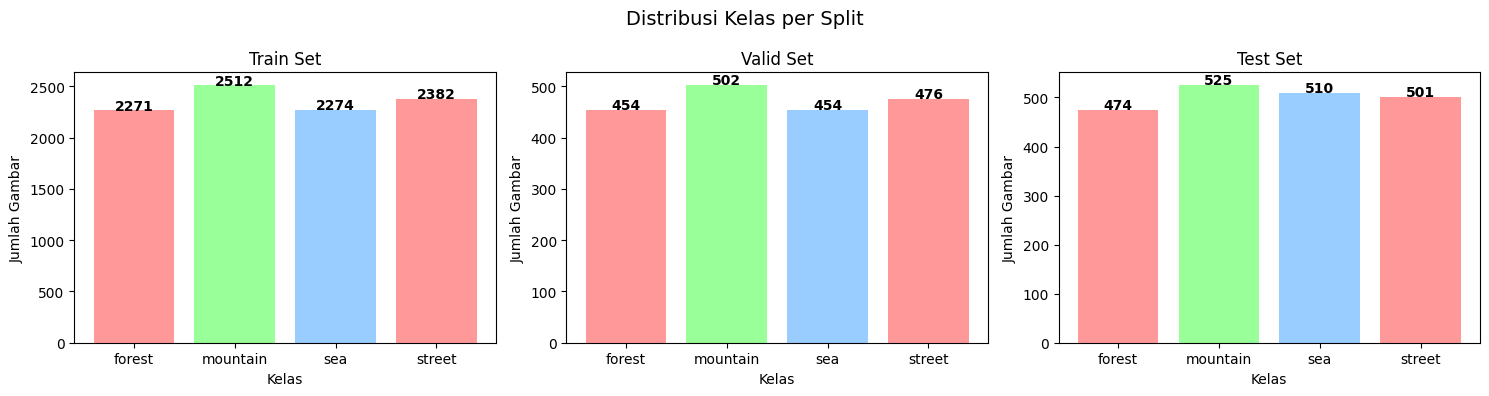

In [5]:
# Hitung jumlah gambar per kelas
print("--- Distribusi Dataset ---")
total_all = 0
for split_name, split_dir in [('Train', train_dir),
                               ('Valid', val_dir),
                               ('Test', test_dir)]:
    print(f"\n{split_name} Set:")
    total_split = 0
    for cls in classes:
        cls_path    = os.path.join(split_dir, cls)
        count       = len(os.listdir(cls_path))
        total_split += count
        print(f"  {cls}: {count} gambar")
    print(f"  Subtotal: {total_split} gambar")
    total_all += total_split

print(f"\nTotal keseluruhan: {total_all} gambar")

# Hitung proporsi split
train_total = sum(len(os.listdir(os.path.join(train_dir, c))) for c in classes)
val_total   = sum(len(os.listdir(os.path.join(val_dir,   c))) for c in classes)
test_total  = sum(len(os.listdir(os.path.join(test_dir,  c))) for c in classes)
grand_total = train_total + val_total + test_total

print("\n--- Proporsi Split ---")
print(f"  Train      : {train_total} gambar ({train_total/grand_total*100:.1f}%)")
print(f"  Valid      : {val_total}  gambar ({val_total/grand_total*100:.1f}%)")
print(f"  Test       : {test_total}  gambar ({test_total/grand_total*100:.1f}%)")

# Visualisasi distribusi kelas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribusi Kelas per Split', fontsize=14)

for idx, (split_name, split_dir) in enumerate([('Train', train_dir),
                                                ('Valid', val_dir),
                                                ('Test', test_dir)]):
    counts = [len(os.listdir(os.path.join(split_dir, cls))) for cls in classes]
    bars   = axes[idx].bar(classes, counts,
                           color=['#FF9999', '#99FF99', '#99CCFF'])
    axes[idx].set_title(f'{split_name} Set')
    axes[idx].set_xlabel('Kelas')
    axes[idx].set_ylabel('Jumlah Gambar')
    for i, v in enumerate(counts):
        axes[idx].text(i, v + 2, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
IMG_SIZE   = (150, 150)
BATCH_SIZE = 32
NUM_CLASSES = len(classes)

# Augmentasi hanya pada data training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Validation dan test hanya rescaling
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("Label kelas       :", train_generator.class_indices)
print("Total batch train :", len(train_generator))
print("Total batch valid :", len(val_generator))
print("Total batch test  :", len(test_generator))

Found 7553 images belonging to 4 classes.
Found 1886 images belonging to 4 classes.
Found 2010 images belonging to 4 classes.
Label kelas       : {'forest': 0, 'mountain': 1, 'sea': 2, 'street': 3}
Total batch train : 237
Total batch valid : 59
Total batch test  : 63


## Modelling

In [7]:
NUM_CLASSES = len(classes)

# Load MobileNetV2
base_model = MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Arsitektur classifier
inputs  = tf.keras.Input(shape=(150, 150, 3))
x       = base_model(inputs, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = Dense(256, activation='relu')(x)
x       = BatchNormalization()(x)
x       = Dropout(0.5)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/tmp/ipykernel_359/4268074063.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,972 (9.87 MB)

 Trainable params: 329,476 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [8]:
# Callback Tahap 1
callbacks = [
    ModelCheckpoint(
        'best_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_accuracy',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

print("TAHAP 1: Training classifier layer\n")
history1 = model.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print(f"\nTahap 1 selesai!")
print(f"Val accuracy terbaik : {max(history1.history['val_accuracy'])*100:.2f}%")
print(f'Train accuracy akhir : {history1.history["accuracy"][-1]*100:.2f}%')

TAHAP 1: Training classifier layer

Epoch 1/30
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.8681 - loss: 0.3962
Epoch 1: val_accuracy improved from None to 0.95917, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
237/237 ━━━━━━━━━━━━━━━━━━━━ 120s 401ms/step - accuracy: 0.9097 - loss: 0.2699 - val_accuracy: 0.9592 - val_loss: 0.1173 - learning_rate: 0.0010
Epoch 2/30
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.9412 - loss: 0.1713
Epoch 2: val_accuracy improved from 0.95917 to 0.96660, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
237/237 ━━━━━━━━━━━━━━━━━━━━ 60s 253ms/step - accuracy: 0.9372 - loss: 0.1800 - val_accuracy: 0.9666 - val_loss: 0.1016 - learning_rate: 0.0010
Epoch 3/30
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.9436 - loss: 0.1571
Epoch 3: val_accuracy improved from 0.96660 to 0.96925, saving model to best_model.keras

Epoch 3: finished saving model to best_mod

In [9]:
# TAHAP 2: Fine Tuning (unfreeze sebagian layer base model)
print('=' * 55)
print('TAHAP 2: Fine Tuning (Unfreeze 50 Layer Terakhir)')
print('=' * 55)

base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

print(f'Layer trainable setelah fine tuning: '
      f'{sum(1 for l in model.layers if l.trainable)}')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks 2
callbacks2 = [
    ModelCheckpoint(
        'best_model_finetune.keras',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_accuracy',
        factor=0.3,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

history2 = model.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=callbacks2,
    verbose=1
)

print(f'\nTahap 2 selesai!')
print(f'Val accuracy terbaik : {max(history2.history["val_accuracy"])*100:.2f}%')
print(f'Train accuracy akhir : {history2.history["accuracy"][-1]*100:.2f}%')

TAHAP 2: Fine Tuning (Unfreeze 50 Layer Terakhir)
Layer trainable setelah fine tuning: 7
Epoch 1/30
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.8742 - loss: 0.3426
Epoch 1: val_accuracy improved from None to 0.94539, saving model to best_model_finetune.keras

Epoch 1: finished saving model to best_model_finetune.keras
237/237 ━━━━━━━━━━━━━━━━━━━━ 104s 326ms/step - accuracy: 0.8925 - loss: 0.2989 - val_accuracy: 0.9454 - val_loss: 0.2155 - learning_rate: 1.0000e-05
Epoch 2/30
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.9179 - loss: 0.2434
Epoch 2: val_accuracy improved from 0.94539 to 0.95122, saving model to best_model_finetune.keras

Epoch 2: finished saving model to best_model_finetune.keras
237/237 ━━━━━━━━━━━━━━━━━━━━ 58s 245ms/step - accuracy: 0.9223 - loss: 0.2203 - val_accuracy: 0.9512 - val_loss: 0.1922 - learning_rate: 1.0000e-05
Epoch 3/30
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.9294 - loss: 0.2020
Epoch 3: val_accuracy improved from

## Evaluasi dan Visualisasi

EVALUASI MODEL PADA TEST SET
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 275ms/step - accuracy: 0.9801 - loss: 0.0501

Train Accuracy : 99.38%
Test Accuracy  : 98.01%
Train Loss     : 0.0226
Test Loss      : 0.0501


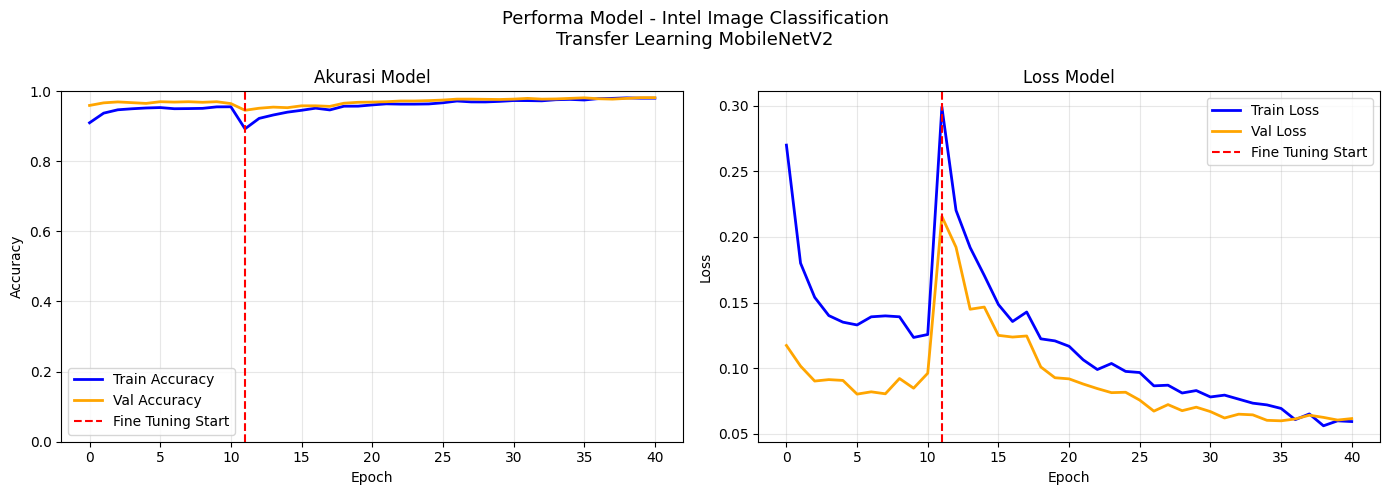

In [10]:
# Evaluasi pada Test Set
print('=' * 50)
print('EVALUASI MODEL PADA TEST SET')
print('=' * 50)

test_loss,  test_acc  = model.evaluate(test_generator,  verbose=1)
train_loss, train_acc = model.evaluate(train_generator, verbose=0)

print(f'\nTrain Accuracy : {train_acc * 100:.2f}%')
print(f'Test Accuracy  : {test_acc  * 100:.2f}%')
print(f'Train Loss     : {train_loss:.4f}')
print(f'Test Loss      : {test_loss:.4f}')

# Gabungkan history tahap 1 dan tahap 2
acc      = history1.history['accuracy']     + history2.history['accuracy']
val_acc  = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss     = history1.history['loss']         + history2.history['loss']
val_loss = history1.history['val_loss']     + history2.history['val_loss']
epochs_range  = range(len(acc))
split_epoch   = len(history1.history['accuracy'])

# Plot Akurasi dan Loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Performa Model - Intel Image Classification\n'
             'Transfer Learning MobileNetV2', fontsize=13)

# Plot Akurasi
axes[0].plot(epochs_range, acc,     label='Train Accuracy',
             color='blue',   linewidth=2)
axes[0].plot(epochs_range, val_acc, label='Val Accuracy',
             color='orange', linewidth=2)
axes[0].axvline(x=split_epoch, color='red',
                linestyle='--', label='Fine Tuning Start')
axes[0].set_title('Akurasi Model')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1])

# Plot Loss
axes[1].plot(epochs_range, loss,     label='Train Loss',
             color='blue',   linewidth=2)
axes[1].plot(epochs_range, val_loss, label='Val Loss',
             color='orange', linewidth=2)
axes[1].axvline(x=split_epoch, color='red',
                linestyle='--', label='Fine Tuning Start')
axes[1].set_title('Loss Model')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Konversi Model

In [13]:
# Simpan sebagai SavedModel
os.makedirs('saved_model', exist_ok=True)

keras_path = 'intel_scene_model.keras'
model.save(keras_path)

loaded_model = tf.keras.models.load_model(keras_path)
tf.saved_model.save(loaded_model, 'saved_model')
print("SavedModel berhasil disimpan!")

# Simpan sebagai TF-Lite
tflite_dir  = 'tflite'
tflite_path = os.path.join(tflite_dir, 'model.tflite')
label_path  = os.path.join(tflite_dir, 'label.txt')
os.makedirs(tflite_dir, exist_ok=True)

converter    = tf.lite.TFLiteConverter.from_saved_model('saved_model')
tflite_model = converter.convert()

with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

# Buat label.txt
with open(label_path, 'w') as f:
    for cls in classes:
        f.write(cls + '\n')

print(f"\n TF-Lite berhasil disimpan | "
      f"Ukuran: {os.path.getsize(tflite_path)/(1024*1024):.2f} MB")

# Simpan sebagai TFjs
loaded_model = tf.keras.models.load_model('intel_scene_model.keras')
print("Model berhasil diload!")

tfjs_path = 'tfjs_model'
os.makedirs(tfjs_path, exist_ok=True)

# Mengambil weights tiap layer
weight_specs = []
weight_data  = []

for layer in loaded_model.layers:
    for weight in layer.weights:
        w_np      = weight.numpy().astype(np.float32)
        byte_data = w_np.tobytes()
        weight_specs.append({
            'name' : weight.name,
            'shape': list(w_np.shape),
            'dtype': 'float32'
        })
        weight_data.append(byte_data)

# Simpan semua weights
all_bytes = b''.join(weight_data)
bin_path  = os.path.join(tfjs_path, 'group1-shard1of1.bin')
with open(bin_path, 'wb') as f:
    f.write(all_bytes)
print(f" File .bin berhasil disimpan ({os.path.getsize(bin_path)/(1024*1024):.2f} MB)")

# Buat model.json
model_json = {
    'format'         : 'layers-model',
    'generatedBy'    : 'TensorFlow.js v4.15.0',
    'convertedBy'    : 'TensorFlow.js Converter v4.15.0',
    'modelTopology'  : json.loads(loaded_model.to_json()),
    'weightsManifest': [{
        'paths'  : ['group1-shard1of1.bin'],
        'weights': weight_specs
    }]
}

json_path = os.path.join(tfjs_path, 'model.json')
with open(json_path, 'w') as f:
    json.dump(model_json, f, indent=2)
print(f" File model.json berhasil disimpan")

saved_model_path = 'intel_scene_model.keras'
tflite_path      = 'tflite/model.tflite'
label_path       = 'tflite/label.txt'
tfjs_json_path   = 'tfjs_model/model.json'
tfjs_bin_path    = 'tfjs_model/group1-shard1of1.bin'

print(f"SavedModel (.keras) : {os.path.exists(saved_model_path)}")
print(f"TF-Lite             : {os.path.exists(tflite_path)}")
print(f"Label               : {os.path.exists(label_path)}")
print(f"TFJS (model.json)   : {os.path.exists(os.path.join(tfjs_path, 'model.json'))}")

SavedModel berhasil disimpan!

 TF-Lite berhasil disimpan | Ukuran: 0.20 MB
Model berhasil diload!
 File .bin berhasil disimpan (9.87 MB)
 File model.json berhasil disimpan
SavedModel (.keras) : True
TF-Lite             : True
Label               : True
TFJS (model.json)   : True


## Inference (Optional)

Inference dengan gambar dari Test Set

>>> Gambar: forest


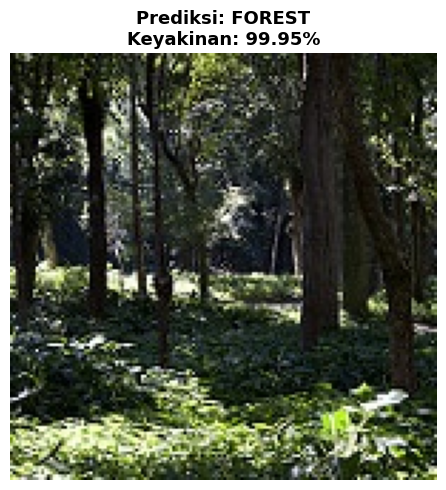


  HASIL KLASIFIKASI WISATA
  Jenis Wisata      : FOREST
  Tingkat Keyakinan : 99.95%
  Bulan Saat Ini    : November

  Distribusi Probabilitas:
    forest      :  99.9% ███████████████████
    mountain    :   0.0% 
    sea         :   0.0% 
    street      :   0.0% 

ALAM & EKOWISATA
  Bulan Berkunjung: November

  Destinasi Terbaik Bulan November:
  TERBAIK Kebun Raya Bogor     | Jawa Barat           | Koleksi Tanaman Langka
  TERBAIK TN Wakatobi          | Sulawesi Tenggara    | Hutan Bawah Laut

  Destinasi yang Masih Bisa Dikunjungi:
  CUKUP BAIK TN Baluran           | Jawa Timur           | Savana & Satwa Liar
  CUKUP BAIK TN Ujung Kulon       | Banten               | Badak Jawa
  CUKUP BAIK TN Bromo Tengger     | Jawa Timur           | Padang Savana Luas
  CUKUP BAIK Mangrove Bali        | Bali                 | Ekowisata Mangrove

  Destinasi yang Sebaiknya Dihindari Bulan Ini:
  HINDARI TN Gunung Leuser     | Aceh                 | Orangutan & Harimau
  HINDARI Hutan Pinus Man

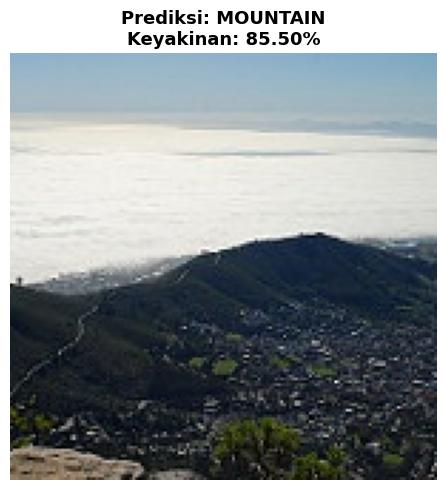


  HASIL KLASIFIKASI WISATA
  Jenis Wisata      : MOUNTAIN
  Tingkat Keyakinan : 85.50%
  Bulan Saat Ini    : November

  Distribusi Probabilitas:
    forest      :   0.0% 
    mountain    :  85.5% █████████████████
    sea         :  14.4% ██
    street      :   0.1% 

PENDAKIAN & PEGUNUNGAN
  Bulan Berkunjung: November

  Destinasi yang Masih Bisa Dikunjungi:
  CUKUP BAIK Merbabu              | Jawa Tengah          | 3.142 mdpl | Sedang
  CUKUP BAIK Bromo                | Jawa Timur           | 2.329 mdpl | Mudah
  CUKUP BAIK Prau                 | Jawa Tengah          | 2.565 mdpl | Mudah
  CUKUP BAIK Papandayan           | Jawa Barat           | 2.665 mdpl | Mudah
  CUKUP BAIK Batur                | Bali                 | 1.717 mdpl | Mudah

  Destinasi yang Sebaiknya Dihindari Bulan Ini:
  HINDARI Semeru               | Jawa Timur           | 3.676 mdpl | Sulit
  HINDARI Rinjani              | NTB                  | 3.726 mdpl | Sulit
  HINDARI Sindoro              | Jawa Tengah  

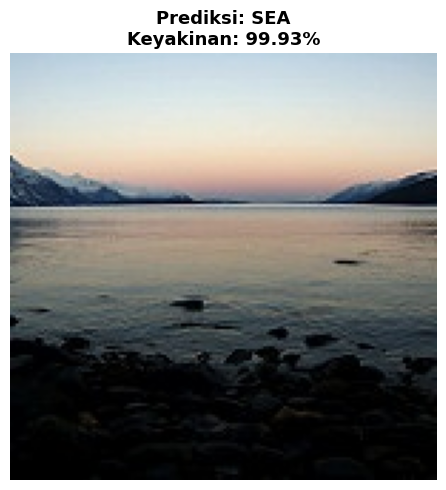


  HASIL KLASIFIKASI WISATA
  Jenis Wisata      : SEA
  Tingkat Keyakinan : 99.93%
  Bulan Saat Ini    : November

  Distribusi Probabilitas:
    forest      :   0.0% 
    mountain    :   0.1% 
    sea         :  99.9% ███████████████████
    street      :   0.0% 

PANTAI & BAHARI
  Bulan Berkunjung: November

  Destinasi Terbaik Bulan November:
  TERBAIK Raja Ampat           | Papua Barat          | Diving & Snorkeling
  TERBAIK Pantai Ora           | Maluku               | Bungalow di Atas Laut

  Destinasi yang Masih Bisa Dikunjungi:
  CUKUP BAIK Kuta Bali            | Bali                 | Surfing & Sunset
  CUKUP BAIK Derawan              | Kalimantan Timur     | Penyu & Ubur-ubur
  CUKUP BAIK Nihiwatu             | NTT                  | Surfing Kelas Dunia
  CUKUP BAIK Tanjung Tinggi       | Bangka Belitung      | Batu Granit Unik
  CUKUP BAIK Senggigi             | NTB                  | Snorkeling & Sunset
  CUKUP BAIK Parangtritis         | DI Yogyakarta        | Wisata Buda

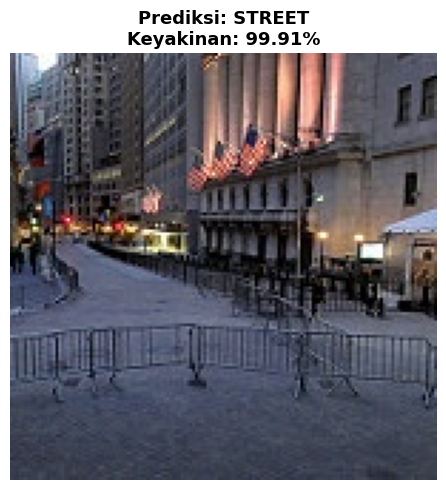


  HASIL KLASIFIKASI WISATA
  Jenis Wisata      : STREET
  Tingkat Keyakinan : 99.91%
  Bulan Saat Ini    : November

  Distribusi Probabilitas:
    forest      :   0.1% 
    mountain    :   0.0% 
    sea         :   0.0% 
    street      :  99.9% ███████████████████

WISATA KULINER & URBAN
  Bulan Berkunjung: November

  Destinasi Terbaik Bulan November:
  TERBAIK Malioboro            | DI Yogyakarta        | Street Food & Batik
  TERBAIK Jalan Sabang         | DKI Jakarta          | Kuliner Malam Legendaris
  TERBAIK Pasar Baru           | Jawa Barat           | Belanja Tekstil Heritage
  TERBAIK Petak Sembilan       | DKI Jakarta          | Kuliner Tionghoa Autentik
  TERBAIK Pasar Beringharjo    | DI Yogyakarta        | Pasar Tradisional Terlengkap
  TERBAIK Pantjoran PIK        | DKI Jakarta          | Kawasan Heritage Tionghoa
  TERBAIK Jalan Alor           | Malaysia             | Kuliner Asia Tenggara
  TERBAIK Jalan Surabaya       | DKI Jakarta          | Pasar Antik Unik

  D

Saving img_test.webp to img_test.webp


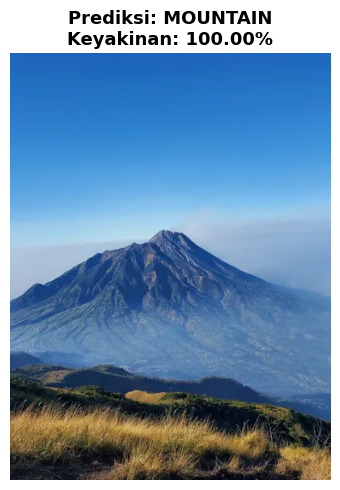


  HASIL KLASIFIKASI WISATA
  Jenis Wisata      : MOUNTAIN
  Tingkat Keyakinan : 100.00%
  Bulan Saat Ini    : November

  Distribusi Probabilitas:
    forest      :   0.0% 
    mountain    : 100.0% ███████████████████
    sea         :   0.0% 
    street      :   0.0% 

PENDAKIAN & PEGUNUNGAN
  Bulan Berkunjung: November

  Destinasi yang Masih Bisa Dikunjungi:
  CUKUP BAIK Merbabu              | Jawa Tengah          | 3.142 mdpl | Sedang
  CUKUP BAIK Bromo                | Jawa Timur           | 2.329 mdpl | Mudah
  CUKUP BAIK Prau                 | Jawa Tengah          | 2.565 mdpl | Mudah
  CUKUP BAIK Papandayan           | Jawa Barat           | 2.665 mdpl | Mudah
  CUKUP BAIK Batur                | Bali                 | 1.717 mdpl | Mudah

  Destinasi yang Sebaiknya Dihindari Bulan Ini:
  HINDARI Semeru               | Jawa Timur           | 3.676 mdpl | Sulit
  HINDARI Rinjani              | NTB                  | 3.726 mdpl | Sulit
  HINDARI Sindoro              | Jawa Tengah 

In [14]:
bulan_sekarang = datetime.datetime.now().month
nama_bulan     = [
    '', 'Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni',
    'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember'
]

# Status bulan per destinasi
# 1=Terbaik, 2=Cukup Baik, 3=Hindari
destinasi_wisata = {
    'mountain': {
        'judul': 'PENDAKIAN & PEGUNUNGAN',
        'destinasi': [
            {'nama': 'Semeru',     'provinsi': 'Jawa Timur',       'info': '3.676 mdpl | Sulit',
             'bulan_terbaik': [6,7,8], 'bulan_ok': [5,9],     'bulan_hindari': [10,11,12,1,2,3,4]},
            {'nama': 'Rinjani',    'provinsi': 'NTB',              'info': '3.726 mdpl | Sulit',
             'bulan_terbaik': [5,6,7,8,9,10], 'bulan_ok': [4], 'bulan_hindari': [11,12,1,2,3]},
            {'nama': 'Merbabu',    'provinsi': 'Jawa Tengah',      'info': '3.142 mdpl | Sedang',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Bromo',      'provinsi': 'Jawa Timur',       'info': '2.329 mdpl | Mudah',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Prau',       'provinsi': 'Jawa Tengah',      'info': '2.565 mdpl | Mudah',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Sindoro',    'provinsi': 'Jawa Tengah',      'info': '3.153 mdpl | Sedang',
             'bulan_terbaik': [6,7,8,9],  'bulan_ok': [4,5,10],   'bulan_hindari': [11,12,1,2,3]},
            {'nama': 'Papandayan', 'provinsi': 'Jawa Barat',       'info': '2.665 mdpl | Mudah',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Batur',      'provinsi': 'Bali',             'info': '1.717 mdpl | Mudah',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Kerinci',    'provinsi': 'Sumatera Barat',   'info': '3.805 mdpl | Sulit',
             'bulan_terbaik': [5,6,7,8,9],  'bulan_ok': [4,10],   'bulan_hindari': [11,12,1,2,3]},
            {'nama': 'Gede',       'provinsi': 'Jawa Barat',       'info': '2.958 mdpl | Sedang',
             'bulan_terbaik': [5,6,7,8,9],  'bulan_ok': [4,10],   'bulan_hindari': [11,12,1,2,3]},
        ]
    },
    'sea': {
        'judul': 'PANTAI & BAHARI',
        'destinasi': [
            {'nama': 'Raja Ampat',      'provinsi': 'Papua Barat',       'info': 'Diving & Snorkeling',
             'bulan_terbaik': [10,11,12,1,2,3,4], 'bulan_ok': [9],  'bulan_hindari': [5,6,7,8]},
            {'nama': 'Labuan Bajo',     'provinsi': 'NTT',               'info': 'Komodo & Island Hopping',
             'bulan_terbaik': [4,5,6,7,8,9],  'bulan_ok': [3,10],  'bulan_hindari': [11,12,1,2]},
            {'nama': 'Pink Beach',      'provinsi': 'NTB',               'info': 'Pantai Unik Pink',
             'bulan_terbaik': [5,6,7,8,9],    'bulan_ok': [4,10],  'bulan_hindari': [11,12,1,2,3]},
            {'nama': 'Kuta Bali',       'provinsi': 'Bali',              'info': 'Surfing & Sunset',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Derawan',         'provinsi': 'Kalimantan Timur',  'info': 'Penyu & Ubur-ubur',
             'bulan_terbaik': [3,4,5,6,7,8,9,10], 'bulan_ok': [2,11], 'bulan_hindari': [12,1]},
            {'nama': 'Pantai Ora',      'provinsi': 'Maluku',            'info': 'Bungalow di Atas Laut',
             'bulan_terbaik': [10,11,12,1,2,3,4], 'bulan_ok': [9],  'bulan_hindari': [5,6,7,8]},
            {'nama': 'Nihiwatu',        'provinsi': 'NTT',               'info': 'Surfing Kelas Dunia',
             'bulan_terbaik': [5,6,7,8,9,10],  'bulan_ok': [4,11],  'bulan_hindari': [12,1,2,3]},
            {'nama': 'Tanjung Tinggi',  'provinsi': 'Bangka Belitung',   'info': 'Batu Granit Unik',
             'bulan_terbaik': [3,4,5,6,7,8,9,10], 'bulan_ok': [2,11], 'bulan_hindari': [12,1]},
            {'nama': 'Senggigi',        'provinsi': 'NTB',               'info': 'Snorkeling & Sunset',
             'bulan_terbaik': [5,6,7,8,9,10],  'bulan_ok': [4,11],  'bulan_hindari': [12,1,2,3]},
            {'nama': 'Parangtritis',    'provinsi': 'DI Yogyakarta',     'info': 'Wisata Budaya Pantai',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
        ]
    },
    'forest': {
        'judul': 'ALAM & EKOWISATA',
        'destinasi': [
            {'nama': 'TN Gunung Leuser',    'provinsi': 'Aceh',              'info': 'Orangutan & Harimau',
             'bulan_terbaik': [5,6,7,8,9],    'bulan_ok': [4,10],  'bulan_hindari': [11,12,1,2,3]},
            {'nama': 'TN Baluran',          'provinsi': 'Jawa Timur',        'info': 'Savana & Satwa Liar',
             'bulan_terbaik': [6,7,8,9,10],   'bulan_ok': [5,11],  'bulan_hindari': [12,1,2,3,4]},
            {'nama': 'Hutan Pinus Mangunan','provinsi': 'DI Yogyakarta',     'info': 'Fotografi & Camping',
             'bulan_terbaik': [5,6,7,8,9],    'bulan_ok': [4,10],  'bulan_hindari': [11,12,1,2,3]},
            {'nama': 'TN Ujung Kulon',      'provinsi': 'Banten',            'info': 'Badak Jawa',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'TN Tanjung Puting',   'provinsi': 'Kalimantan Tengah', 'info': 'Orangutan & Klotok',
             'bulan_terbaik': [6,7,8,9],      'bulan_ok': [5,10],  'bulan_hindari': [11,12,1,2,3,4]},
            {'nama': 'Kebun Raya Bogor',    'provinsi': 'Jawa Barat',        'info': 'Koleksi Tanaman Langka',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'TN Bromo Tengger',    'provinsi': 'Jawa Timur',        'info': 'Padang Savana Luas',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11], 'bulan_hindari': [12,1,2]},
            {'nama': 'Mangrove Bali',       'provinsi': 'Bali',              'info': 'Ekowisata Mangrove',
             'bulan_terbaik': [5,6,7,8,9,10],   'bulan_ok': [4,11], 'bulan_hindari': [12,1,2,3]},
            {'nama': 'TN Wakatobi',         'provinsi': 'Sulawesi Tenggara', 'info': 'Hutan Bawah Laut',
             'bulan_terbaik': [10,11,12,1,2,3,4], 'bulan_ok': [9],  'bulan_hindari': [5,6,7,8]},
            {'nama': 'TN Komodo',           'provinsi': 'NTT',               'info': 'Komodo Dragon',
             'bulan_terbaik': [4,5,6,7,8,9],  'bulan_ok': [3,10],  'bulan_hindari': [11,12,1,2]},
        ]
    },
    'street': {
        'judul': 'WISATA KULINER & URBAN',
        'destinasi': [
            {'nama': 'Malioboro',        'provinsi': 'DI Yogyakarta',  'info': 'Street Food & Batik',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Jalan Sabang',     'provinsi': 'DKI Jakarta',    'info': 'Kuliner Malam Legendaris',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Pasar Baru',       'provinsi': 'Jawa Barat',     'info': 'Belanja Tekstil Heritage',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Petak Sembilan',   'provinsi': 'DKI Jakarta',    'info': 'Kuliner Tionghoa Autentik',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Pasar Beringharjo','provinsi': 'DI Yogyakarta',  'info': 'Pasar Tradisional Terlengkap',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Night Market Seminyak','provinsi': 'Bali',       'info': 'Kuliner Internasional',
             'bulan_terbaik': [4,5,6,7,8,9,10], 'bulan_ok': [3,11],   'bulan_hindari': [12,1,2]},
            {'nama': 'Pasar Seni Sukawati','provinsi': 'Bali',         'info': 'Kerajinan Tangan',
             'bulan_terbaik': [5,6,7,8,9,10],   'bulan_ok': [4,11],   'bulan_hindari': [12,1,2,3]},
            {'nama': 'Pantjoran PIK',    'provinsi': 'DKI Jakarta',    'info': 'Kawasan Heritage Tionghoa',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Jalan Alor',       'provinsi': 'Malaysia',       'info': 'Kuliner Asia Tenggara',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
            {'nama': 'Jalan Surabaya',   'provinsi': 'DKI Jakarta',    'info': 'Pasar Antik Unik',
             'bulan_terbaik': [1,2,3,4,5,6,7,8,9,10,11,12], 'bulan_ok': [], 'bulan_hindari': []},
        ]
    }
}

# FUNGSI REKOMENDASI WISATA
def get_status_bulan(destinasi, bulan):
    if bulan in destinasi['bulan_terbaik']:
        return 'TERBAIK'
    elif bulan in destinasi['bulan_ok']:
        return 'CUKUP BAIK'
    else:
        return 'HINDARI'

def tampilkan_rekomendasi(kelas, bulan):
    data   = destinasi_wisata[kelas]
    print(f"\n{'='*60}")
    print(f"{data['judul']}")
    print(f"  Bulan Berkunjung: {nama_bulan[bulan]}")
    print(f"{'='*60}")

    terbaik  = []
    cukup    = []
    hindari  = []

    for dest in data['destinasi']:
        status = get_status_bulan(dest, bulan)
        baris  = f"  {status} {dest['nama']:20s} | {dest['provinsi']:20s} | {dest['info']}"
        if 'TERBAIK' in status:
            terbaik.append(baris)
        elif 'CUKUP' in status:
            cukup.append(baris)
        else:
            hindari.append(baris)

    if terbaik:
        print(f"\n  Destinasi Terbaik Bulan {nama_bulan[bulan]}:")
        for b in terbaik:
            print(b)
    if cukup:
        print(f"\n  Destinasi yang Masih Bisa Dikunjungi:")
        for b in cukup:
            print(b)
    if hindari:
        print(f"\n  Destinasi yang Sebaiknya Dihindari Bulan Ini:")
        for b in hindari:
            print(b)
    print(f"{'='*60}")

# FUNGSI PREDIKSI UTAMA
class_labels = {v: k for k, v in train_generator.class_indices.items()}

def predict_scene(img_path, bulan=None):
    if bulan is None:
        bulan = datetime.datetime.now().month

    # Preprocessing gambar
    img         = Image.open(img_path).convert('RGB')
    img_resized = img.resize((150, 150))
    img_array   = np.array(img_resized) / 255.0
    img_array   = np.expand_dims(img_array, axis=0)

    # Prediksi
    prediction      = model.predict(img_array, verbose=0)
    predicted_index = np.argmax(prediction)
    predicted_label = class_labels[predicted_index]
    confidence      = prediction[0][predicted_index] * 100

    # Tampilkan gambar
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediksi: {predicted_label.upper()}\nKeyakinan: {confidence:.2f}%",
              fontsize=13, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # Tampilkan hasil klasifikasi
    print(f"\n{'='*60}")
    print(f"  HASIL KLASIFIKASI WISATA")
    print(f"{'='*60}")
    print(f"  Jenis Wisata      : {predicted_label.upper()}")
    print(f"  Tingkat Keyakinan : {confidence:.2f}%")
    print(f"  Bulan Saat Ini    : {nama_bulan[bulan]}")
    print(f"\n  Distribusi Probabilitas:")
    for i in range(NUM_CLASSES):
        cls  = class_labels[i]
        prob = prediction[0][i] * 100
        bar  = '█' * int(prob / 5)
        print(f"    {cls:12s}: {prob:5.1f}% {bar}")

    # Tampilkan rekomendasi wisata
    if predicted_label in destinasi_wisata:
        tampilkan_rekomendasi(predicted_label, bulan)

# Inference dengan gambar dari test set
print('Inference dengan gambar dari Test Set')
for cls in classes:
    sample_path = os.path.join(
        test_dir, cls,
        os.listdir(os.path.join(test_dir, cls))[0]
    )
    print(f'\n>>> Gambar: {cls}')
    predict_scene(sample_path)
    print()

# Inference dengan gambar baru
print('\n --Coba dengan gambar baru--')
from google.colab import files
uploaded_imgs = files.upload()
for img_name in uploaded_imgs.keys():
    predict_scene(img_name)